# NADE beyond pictures (text and speech)

# NADE model
Write rules `W`, read rules `V`, starting leans `b`, start memory `c`. Defined here so Part A can use it.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class NADE(nn.Module):
    """Neural Autoregressive Distribution Estimator (NADE).
    
    Models binary vector distributions by predicting each pixel/feature 
    conditioned on all previous pixels.
    
    Attributes:
        D (int): Input feature dimension (e.g., 100 for text, 512 for speech).
        H (int): Hidden layer dimension (e.g., 50).
        W (nn.Parameter): Weight matrix for updating memory state, shape (D, H).
        V (nn.Parameter): Read weight matrix for predicting logits, shape (D, H).
        b (nn.Parameter): Output bias vector, shape (D,).
        c (nn.Parameter): Initial hidden memory state, shape (H,).
    """

    def __init__(self, D: int, H: int):
        """Initializes NADE layer parameters.

        Args:
            D (int): Input dimension (number of features/pixels).
            H (int): Hidden state dimension.
        """
        super().__init__()
        self.D = D
        self.H = H
        
        # Trainable parameters
        self.W = nn.Parameter(torch.randn(D, H))
        self.V = nn.Parameter(torch.randn(D, H))
        self.b = nn.Parameter(torch.zeros(D))
        self.c = nn.Parameter(torch.zeros(H))
          
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Computes unnormalized prediction logits for each feature.

        Args:
            x (torch.Tensor): Binary input tensor of shape (batch_size, D).

        Returns:
            torch.Tensor: Logits tensor of shape (batch_size, D).
        """
        batch_size = x.size(0)
        # Expand initial memory c across batch dimension: shape (batch_size, H)
        memory = self.c.repeat(batch_size, 1)
        logits = []
        
        for i in range(self.D):
            # 1. Compute hidden representation for step i: shape (batch_size, H)
            h = torch.sigmoid(memory)
            
            # 2. Compute logit prediction for pixel i: shape (batch_size,)
            z = self.b[i] + (h * self.V[i]).sum(dim=1)
            logits.append(z)
            
            # 3. Update memory using true pixel i value: shape (batch_size, H)
            memory = memory + x[:, i].unsqueeze(1) * self.W[i]
        
        # Stack logits along feature dimension: shape (batch_size, D)
        return torch.stack(logits, dim=1)
    
    def sample(self, num_samples: int) -> torch.Tensor:
        """Generates new synthetic binary samples pixel-by-pixel.

        Args:
            num_samples (int): Number of binary vectors to generate.

        Returns:
            torch.Tensor: Generated binary samples of shape (num_samples, D).
        """
        # Detect which device the model weights are currently on
        device = self.W.device
        
        samples = torch.zeros((num_samples, self.D), device=device)
        memory = self.c.unsqueeze(0).expand(num_samples, -1) # ensure memory is on same device
        
        for i in range(self.D):
            # Compute hidden state and prediction probability for pixel i
            h = torch.sigmoid(memory)
            z = self.b[i] + (h * self.V[i]).sum(dim=1)
            p_i = torch.sigmoid(z)
            
            # Draw binary choice (0 or 1) based on computed probability
            x_i = torch.bernoulli(p_i)
            samples[:, i] = x_i
            
            # Update memory state using generated binary sample
            memory = memory + samples[:, i].unsqueeze(1) * self.W[i]
        
        return samples
    
    def compute_surprise(self, x: torch.Tensor) -> torch.Tensor:
        """Computes average surprise (binary cross-entropy loss) per pixel.

        Args:
            x (torch.Tensor): Input binary tensor of shape (batch_size, D).

        Returns:
            torch.Tensor: Scalar tensor containing average surprise per pixel.
        """
        logits = self.forward(x)
        return F.binary_cross_entropy_with_logits(logits, x)

# Part A. Text: train on normal SMS messages only, then show NADE spam

# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import re

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.optim import Adam

from datasets import load_dataset
from collections import Counter

EPOCHS = 15
D_TXT = 100
H_TXT = 50
LR = 1e-3

# Pick GPU automatically if available, otherwise CPU — every later cell reuses `device`.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())
print("Using device    :", device)

c:\Users\alira\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version : 2.6.0+cu124
CUDA available  : True
Using device    : cuda


# Dataset

In [2]:
dataset = load_dataset("ucirvine/sms_spam")

In [3]:
dataset.keys()

print('column names: ', dataset['train'].column_names)
print('first row : ', dataset['train'][0])

column names:  ['sms', 'label']
first row :  {'sms': 'Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...\n', 'label': 0}


In [4]:
dataset['train']['sms'][:4]

['Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...\n',
 'Ok lar... Joking wif u oni...\n',
 "Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's\n",
 'U dun say so early hor... U c already then say...\n']

In [5]:
def clean_text(sms):
    clean_sms = []
    
    for text in sms:
        clean_text = re.sub(r"[^a-zA-Z\s]", "", text)
        clean_text = clean_text.lower().split()
        clean_sms.append(clean_text)
    
    return clean_sms

In [6]:
X = clean_text(dataset['train']['sms'])
X[0]

['go',
 'until',
 'jurong',
 'point',
 'crazy',
 'available',
 'only',
 'in',
 'bugis',
 'n',
 'great',
 'world',
 'la',
 'e',
 'buffet',
 'cine',
 'there',
 'got',
 'amore',
 'wat']

## Vocabulary creation
top 100 most frequent words

In [7]:
def get_freqs(x):
    counter = Counter()
    
    for sms in x:
        counter.update(sms)
    
    return counter

In [8]:
freqs = get_freqs(X)
freqs

Counter({'to': 2251,
         'i': 2249,
         'you': 2128,
         'a': 1448,
         'the': 1334,
         'u': 1156,
         'and': 971,
         'is': 893,
         'in': 891,
         'me': 791,
         'my': 759,
         'for': 711,
         'your': 677,
         'it': 622,
         'of': 622,
         'call': 581,
         'have': 576,
         'on': 536,
         'that': 514,
         'are': 490,
         'now': 479,
         'im': 476,
         'so': 439,
         'not': 436,
         'but': 432,
         'or': 417,
         'at': 405,
         'can': 405,
         'do': 401,
         'ur': 390,
         'get': 390,
         'be': 385,
         'will': 383,
         'if': 383,
         'with': 382,
         'just': 368,
         'no': 352,
         'we': 351,
         'this': 330,
         'its': 315,
         'up': 307,
         'dont': 298,
         'when': 287,
         'go': 285,
         'from': 279,
         'ok': 278,
         'free': 278,
         'ltgt': 276,


In [9]:
vocab = [word for word, count in freqs.most_common(100)]
# len(vocab)
vocab

['to',
 'i',
 'you',
 'a',
 'the',
 'u',
 'and',
 'is',
 'in',
 'me',
 'my',
 'for',
 'your',
 'it',
 'of',
 'call',
 'have',
 'on',
 'that',
 'are',
 'now',
 'im',
 'so',
 'not',
 'but',
 'or',
 'at',
 'can',
 'do',
 'ur',
 'get',
 'be',
 'will',
 'if',
 'with',
 'just',
 'no',
 'we',
 'this',
 'its',
 'up',
 'dont',
 'when',
 'go',
 'from',
 'ok',
 'free',
 'ltgt',
 'all',
 'out',
 'how',
 'what',
 'know',
 'like',
 'ill',
 'got',
 'good',
 'then',
 'was',
 'am',
 'come',
 'only',
 'day',
 'time',
 'love',
 'there',
 'want',
 'send',
 'text',
 'he',
 'as',
 'by',
 'going',
 'one',
 'need',
 'about',
 'txt',
 'home',
 'lor',
 'see',
 'sorry',
 'stop',
 'still',
 'r',
 'back',
 'our',
 'n',
 'reply',
 'today',
 'mobile',
 'tell',
 'new',
 'well',
 'hi',
 'later',
 'think',
 'da',
 'been',
 'she',
 'please']

In [10]:
def binarize(x, vocab):
    x_set = set(x)
    return torch.tensor([1.0 if word in x_set else 0.0 for word in vocab])

In [11]:
def process_dataset(dataset):
    processed_txt = clean_text(dataset['train']['sms'])
    freqs = get_freqs(processed_txt)
    vocab = [word for word, count in freqs.most_common(100)]
    
    X = torch.stack([binarize(sms, vocab) for sms in processed_txt])
    y = torch.tensor(dataset['train']['label'])
    
    return X, y, vocab, freqs

In [12]:
X, y, vocab, freqs = process_dataset(dataset)

print("Dataset shape:", X.shape)
print('lables:       ', y.shape)

Dataset shape: torch.Size([5574, 100])
lables:        torch.Size([5574])


In [13]:
# Filter normal (label 0) and spam (label 1) messages
X_normal = X[y == 0]
X_spam = X[y == 1]

# Create dataset with normal messages only
normal_dataset = TensorDataset(X_normal)

train_size = int(0.8 * len(normal_dataset))
test_size = len(normal_dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, test_dataset = random_split(
    normal_dataset,
    [train_size, test_size],
    generator=generator
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Normal Train: {len(train_dataset)} | Normal Test: {len(test_dataset)} | Spam Set: {len(X_spam)}")

Normal Train: 3861 | Normal Test: 966 | Spam Set: 747


# Training

In [17]:
def text_train_loop(train_loader, model, optimizer, epochs=EPOCHS, device= "cpu"):
    model.train()
    surprise_history = []  # Stores average surprise per epoch

    for epoch in range(1, epochs + 1):
        total_loss = 0.0

        for (inputs,) in train_loader:
            inputs = inputs.to(device)

            optimizer.zero_grad()

            # 2. Calculate average surprise loss
            loss = model.compute_surprise(inputs)

            # 3. Compute gradients and update weights
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        # Compute average loss for the current epoch
        avg_loss = total_loss / len(train_loader)
        surprise_history.append(avg_loss)
        print(f"Epoch [{epoch}/{epochs}] - Loss (Surprise): {avg_loss:.4f}")

    return surprise_history

In [18]:
txt_model = NADE(D_TXT, H_TXT)
txt_model = txt_model.to(device)
# criterion = nn.BCEWithLogitsLoss()
optimizer = Adam(txt_model.parameters(), lr= LR)

In [19]:
superise_history = text_train_loop(
    train_loader,
    txt_model,
    optimizer,
    EPOCHS,
    device
)

Epoch [1/15] - Loss (Surprise): 1.1053
Epoch [2/15] - Loss (Surprise): 0.4938
Epoch [3/15] - Loss (Surprise): 0.3207
Epoch [4/15] - Loss (Surprise): 0.2746
Epoch [5/15] - Loss (Surprise): 0.2586
Epoch [6/15] - Loss (Surprise): 0.2502
Epoch [7/15] - Loss (Surprise): 0.2445
Epoch [8/15] - Loss (Surprise): 0.2398
Epoch [9/15] - Loss (Surprise): 0.2355
Epoch [10/15] - Loss (Surprise): 0.2321
Epoch [11/15] - Loss (Surprise): 0.2287
Epoch [12/15] - Loss (Surprise): 0.2258
Epoch [13/15] - Loss (Surprise): 0.2232
Epoch [14/15] - Loss (Surprise): 0.2206
Epoch [15/15] - Loss (Surprise): 0.2183


In [20]:
with torch.no_grad():
    samples = txt_model.sample(num_samples= 10)

print("Samples shape:", samples.shape)  # Should be (5, 100)
print("First generated binary vector:\n", samples[0])

Samples shape: torch.Size([10, 100])
First generated binary vector:
 tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 1., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')


In [21]:
# Convert vocabulary list to a NumPy array for fast boolean masking
vocab_np = np.array(vocab)

samples_np = samples.cpu().numpy()

# Decode each generated binary vector
for idx, sample in enumerate(samples_np):
    # Vectorized indexing: select words where sample indicator is 1.0
    decoded_words = vocab_np[sample == 1.0].tolist()
    
    print(f"Generated Message {idx + 1}: {decoded_words}")

Generated Message 1: ['i', 'are', 'can']
Generated Message 2: ['for', 'at', 'home', 'she']
Generated Message 3: ['for', 'going']
Generated Message 4: ['you', 'a', 'is', 'your', 'of', 'or', 'at', 'all', 'he']
Generated Message 5: ['the']
Generated Message 6: ['to', 'i', 'a', 'and', 'me', 'are', 'now', 'im', 'can', 'send']
Generated Message 7: ['now', 'what', 'day', 'going', 'well']
Generated Message 8: ['u', 'do']
Generated Message 9: ['but', 'we', 'see', 'reply']
Generated Message 10: ['in', 'from', 'back']


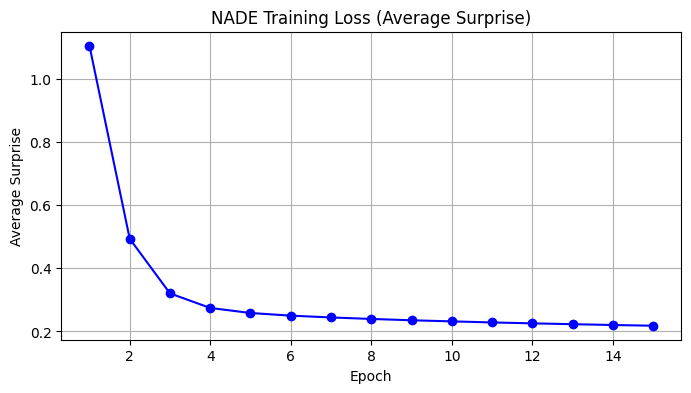

In [22]:
plt.figure(figsize= (8, 4))
plt.plot(
    range(1, len(superise_history) + 1),
    superise_history,
    marker = 'o',
    color = 'b'
)

plt.title("NADE Training Loss (Average Surprise)")
plt.xlabel("Epoch")
plt.ylabel("Average Surprise")
plt.grid(True)
plt.show()


In [23]:
def get_message_surprises(model, data_tensor, device):
    model.eval()
    with torch.no_grad():
        data_tensor = data_tensor.to(device)
        # Compute raw logits for all messages in the tensor
        logits = model(data_tensor)
        
        # Calculate surprise per feature, then take mean across the 100 word features
        surprise_per_message = F.binary_cross_entropy_with_logits(
            logits, data_tensor, reduction='none'
        ).mean(dim=1)
        
    return surprise_per_message.cpu().numpy()

# 1. Combine normal test batches into one tensor
normal_test_X = torch.cat([batch[0] for batch in test_loader])

# 2. Get surprise scores for both sets
normal_surprises = get_message_surprises(txt_model, normal_test_X, device)
spam_surprises = get_message_surprises(txt_model, X_spam, device)

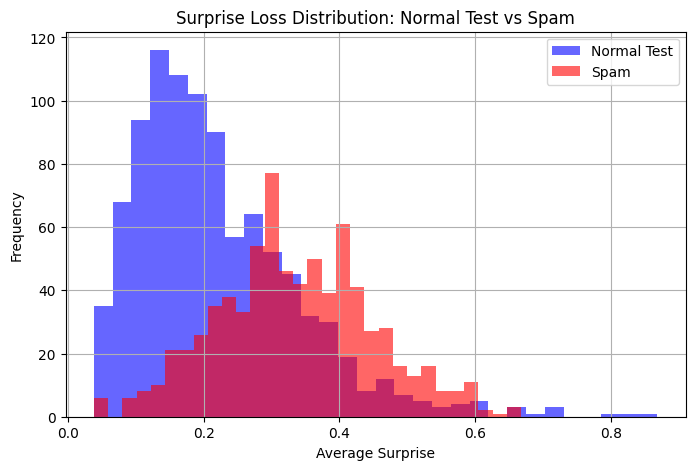

In [24]:
plt.figure(figsize=(8, 5))

# Overlay histograms for both groups
plt.hist(normal_surprises, bins=30, alpha=0.6, label='Normal Test', color='blue')
plt.hist(spam_surprises, bins=30, alpha=0.6, label='Spam', color='red')

plt.xlabel("Average Surprise")
plt.ylabel("Frequency")
plt.title("Surprise Loss Distribution: Normal Test vs Spam")
plt.legend()
plt.grid(True)
plt.show()

In [25]:
# Frequency of each word in spam vs normal messages
spam_freq = X_spam.sum(dim=0) / len(X_spam)
normal_freq = X_normal.sum(dim=0) / len(X_normal)

# 1. Compute the difference in word frequencies (Spam frequency minus Normal frequency)
freq_diff = spam_freq - normal_freq

# 2. Extract indices of the top 10 largest positive differences
top10_indices = torch.topk(freq_diff, k=10).indices.cpu().numpy()

# 3. Map the indices back to words using our vocabulary array
top10_spam_words = vocab_np[top10_indices].tolist()

print("Top 10 words much more common in spam:", top10_spam_words)

Top 10 words much more common in spam: ['call', 'to', 'your', 'free', 'a', 'or', 'txt', 'now', 'for', 'mobile']


# Is spam more surprising? Why, if NADE never saw spam?
NADE was trained exclusively on normal SMS messages, learning the joint probability distribution $P(x) = \prod_{i=1}^{D} P(x_i \mid x_{<i})$ of typical regular text. Spam messages frequently contain specific vocabulary (e.g., call, free, claim, mobile) and unusual word co-occurrences that are rare or absent in normal messages. When evaluating spam, NADE assigns very low conditional probabilities to these unexpected word combinations. Because surprise is measured as negative log-likelihood ($-\log P(x)$), these low probabilities result in significantly higher average surprise scores for spam compared to normal test messages 📉. Consequently, NADE acts as an effective anomaly detector without ever seeing spam during training 🎯.


# Part B. Speech: spoken digits

In [6]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np, librosa, matplotlib.pyplot as plt
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"

class NADE(nn.Module):
    """Model binary feature vectors autoregressively."""

    def __init__(self, D: int, H: int):
        super().__init__()
        self.D = D
        self.H = H
        self.W = nn.Parameter(torch.randn(D, H) * 0.01)
        self.V = nn.Parameter(torch.randn(D, H) * 0.01)
        self.b = nn.Parameter(torch.zeros(D))
        self.c = nn.Parameter(torch.zeros(H))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        memory = self.c.expand(x.size(0), -1)
        logits = []
        for i in range(self.D):
            h = torch.sigmoid(memory)
            logits.append(self.b[i] + (h * self.V[i]).sum(dim=1))
            memory = memory + x[:, i].unsqueeze(1) * self.W[i]
        return torch.stack(logits, dim=1)

    @torch.no_grad()
    def sample(self, num_samples: int) -> torch.Tensor:
        memory = self.c.expand(num_samples, -1).clone()
        samples = torch.zeros(
            num_samples, self.D, device=self.W.device, dtype=self.W.dtype
        )
        for i in range(self.D):
            h = torch.sigmoid(memory)
            probability = torch.sigmoid(self.b[i] + (h * self.V[i]).sum(dim=1))
            samples[:, i] = torch.bernoulli(probability)
            memory = memory + samples[:, i].unsqueeze(1) * self.W[i]
        return samples

    def compute_surprise(self, x: torch.Tensor) -> torch.Tensor:
        logits = self.forward(x)
        return F.binary_cross_entropy_with_logits(logits, x)

def surprise(model, X, bs=256):  # average surprise per pixel, per example
    model.eval(); res = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = X[i:i+bs].to(device)
            res.append(F.binary_cross_entropy_with_logits(model(xb), xb, reduction="none").mean(1).cpu())
    return torch.cat(res)

def train(model, X, epochs, bs=64, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    curve = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X)); tot = 0
        for i in range(0, len(X), bs):
            xb = X[perm[i:i+bs]].to(device)
            loss = model.compute_surprise(xb)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(xb)
        curve.append(tot / len(X)); print(ep+1, round(curve[-1], 4))
    return curve

DatasetDict({
    train: Dataset({
        features: ['audio', 'label'],
        num_rows: 2700
    })
    test: Dataset({
        features: ['audio', 'label'],
        num_rows: 300
    })
})
torch.Size([2700, 512]) torch.Size([300, 512])


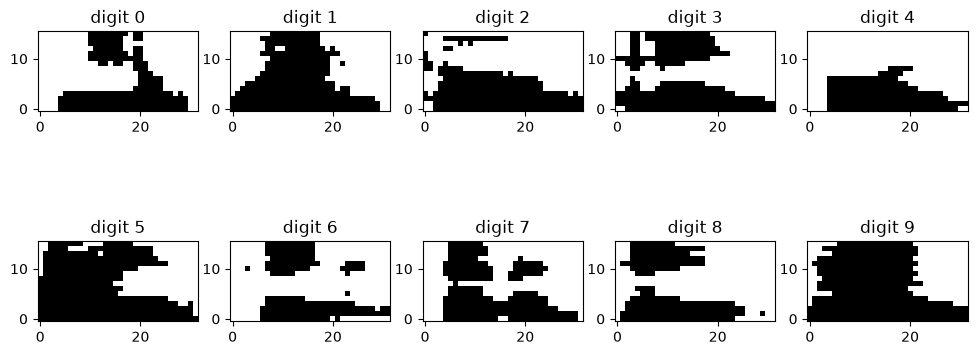

In [8]:
import soundfile as sf, io
from datasets import Audio

# decode audio with soundfile (no torchcodec/FFmpeg needed on Windows)
ds = load_dataset("mteb/free-spoken-digit-dataset").cast_column("audio", Audio(decode=False))
print(ds)   # check the split names and column names (usually 'audio' and 'label')

def to_bits(example):
    y, sr = sf.read(io.BytesIO(example["audio"]["bytes"]), dtype="float32")
    y, _ = librosa.effects.trim(y, top_db=20)                 # cut silence
    mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=16, n_fft=256, hop_length=32)
    mel = F.adaptive_avg_pool1d(torch.tensor(mel)[None], 32)[0].numpy()   # exactly 32 time steps -> (16, 32)
    db = librosa.power_to_db(mel, ref=np.max)                 # 0 dB = loudest moment
    bits = (db > -30).astype(np.float32).T                    # (32 time, 16 pitch)
    return bits.reshape(-1)                                   # 512, time-major

def convert(split):
    X = np.stack([to_bits(e) for e in ds[split]])
    return torch.tensor(X), torch.tensor(ds[split]["label"])

Xtr, ytr = convert("train"); Xte, yte = convert("test")
print(Xtr.shape, Xte.shape)    # (2700, 512) (300, 512)

# one picture per digit
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for d in range(10):
    img = Xtr[ytr == d][0].reshape(32, 16).T       # pitch up, time right
    ax[d//5, d%5].imshow(img, origin="lower", cmap="gray_r"); ax[d//5, d%5].set_title(f"digit {d}")
plt.show()

1 0.5594
2 0.4702
3 0.4608
4 0.4561
5 0.4507
6 0.4418
7 0.4305
8 0.4189
9 0.4064
10 0.3931
11 0.38
12 0.3674
13 0.3559
14 0.345
15 0.3353
16 0.3264
17 0.3185
18 0.3117
19 0.3054
20 0.3
21 0.295
22 0.2906
23 0.2864
24 0.2826
25 0.2789
26 0.2755
27 0.2723
28 0.2693
29 0.2663
30 0.2635


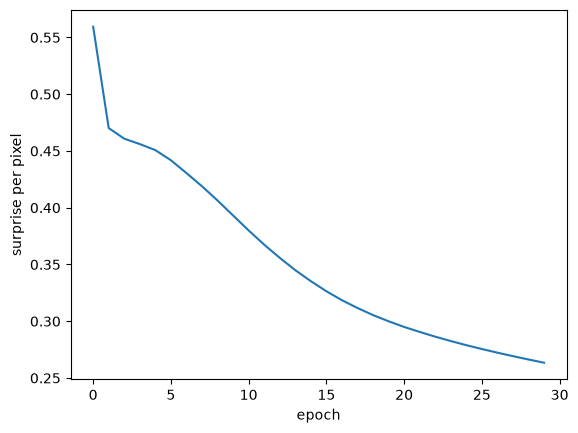

In [9]:
speech_nade = NADE(512, 50).to(device)
curve = train(speech_nade, Xtr, epochs=30)
plt.plot(curve); plt.xlabel("epoch"); plt.ylabel("surprise per pixel"); plt.show()

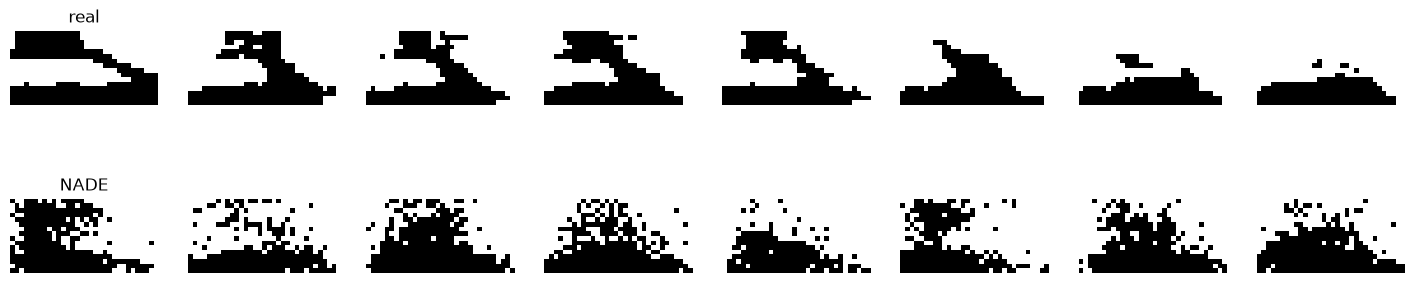

In [10]:
samples = speech_nade.sample(8).cpu()
fig, ax = plt.subplots(2, 8, figsize=(18, 4))
for i in range(8):
    ax[0, i].imshow(Xte[i].reshape(32, 16).T, origin="lower", cmap="gray_r"); ax[0, i].axis("off")
    ax[1, i].imshow(samples[i].reshape(32, 16).T, origin="lower", cmap="gray_r"); ax[1, i].axis("off")
ax[0, 0].set_title("real"); ax[1, 0].set_title("NADE")
plt.show()

{'real': 0.26456117630004883, 'backwards': 0.41136032342910767, 'upside-down': 0.6764011979103088}


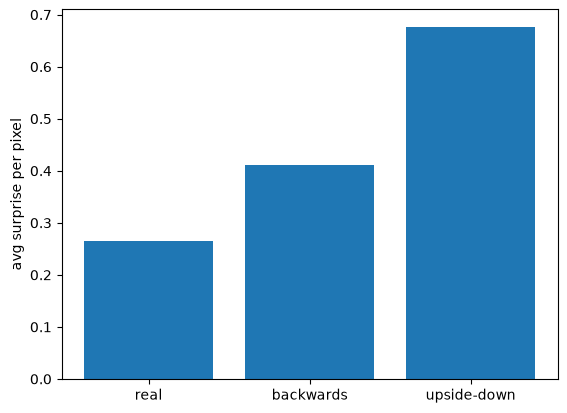

In [11]:
Xr = Xte.reshape(-1, 32, 16)
back = Xr.flip(1).reshape(-1, 512)    # flip time
upside = Xr.flip(2).reshape(-1, 512)  # flip pitch

scores = {"real": surprise(speech_nade, Xte).mean().item(),
          "backwards": surprise(speech_nade, back).mean().item(),
          "upside-down": surprise(speech_nade, upside).mean().item()}
print(scores)
plt.bar(scores.keys(), scores.values()); plt.ylabel("avg surprise per pixel"); plt.show()

In [ ]:
# Report the measured ranking from this run (not assumed)
ranked = sorted(scores.items(), key=lambda kv: kv[1])
print(" < ".join(f"{name} ({val:.3f})" for name, val in ranked))
print("Most surprising:", ranked[-1][0])
print("Expected order holds:", [n for n, _ in ranked] == ["real", "backwards", "upside-down"])

## Interpretation of the surprise scores

Average surprise per pixel on the 300 test spectrograms:

| Test input | Surprise per pixel |
|---|---|
| real | 0.265 |
| backwards (time flipped) | 0.411 |
| upside-down (pitch flipped) | 0.676 |

**Measured ranking: real < backwards < upside-down.** The values above come from one training run; the code cell above recomputes the ranking from the current run, and re-running with a different random seed shifts the numbers slightly (e.g. 0.264 / 0.410 / 0.683) without changing the order.

**What the result shows.**
- Real spectrograms are the least surprising, as expected, because they are the kind of data the model was trained on.
- Both distortions raise the surprise, so the model is sensitive to how speech spectrograms are laid out in time and pitch.
- The upside-down pictures were the most surprising, with a surprise about 2.5x that of real data, versus about 1.6x for backwards.



# Part C. Together

## C1. In MNIST one pixel meant one dot of the image. What does one pixel mean in Part A? In Part B?

**Part A (text):** one pixel is one word of the vocabulary. Pixel *i* is 1 if the *i*-th most common word appears anywhere in the message and 0 if it does not, so the row of 100 pixels is a yes/no checklist of words. The pixels are ordered by word frequency (pixel 0 is "to", pixel 1 is "i", ...), not by where the words appear in the message. NADE therefore predicts "is this word in the message?" given which of the more common words are already present.

**Part B (speech):** one pixel is one cell of the time × pitch grid: whether one of the 16 mel (pitch) bands is louder than −30 dB at one of the 32 time steps. 1 means that pitch band is loud at that moment, 0 means it is quiet. The 512 pixels are read time-major (all 16 pitch bands of step 1, then step 2, ...), so NADE listens to the recording moment by moment, left to right.

## C2. What information did we throw away when we turned messages and recordings into 0/1?

**Text:** we threw away **word order**: "call me now" and "now me call" become the same row. We also lost **how many times** a word appears (only present / absent is kept), every word outside the top 100 (rare words, names, phone numbers), and all digits, punctuation and capital letters, which `clean_text` removes. This is why the samples in Part A look like bags of words rather than real sentences.

**Speech:** we threw away **loudness**: each pixel only says "above or below −30 dB", so a loud and a barely-loud sound both become 1, and because the threshold is relative to the loudest moment of each clip the absolute volume is lost too. We also lost fine detail in time and pitch (only 32 time steps and 16 mel bands), the real duration and speed of the word (silence is trimmed and every clip is squeezed to 32 steps), and the phase, so the original sound cannot be played back from the picture.